*Text under CC-BY 4.0, code under BSD-3-Clause. (c) 2026 Francesco Mario Antonio Mitrotta.*

# Polynomial Chaos Expansion on a Function Whose Answer Is Known

[NB6](06_open_hole_tension.ipynb) built a deterministic open-hole tension (OHT) model that takes about five minutes per run on its coarsest mesh, M1, and almost six hours on its finest, M4. [NB5](05_sobol_indices.ipynb) showed that between 700 and 1600 samples are needed to converge the 95% confidence interval for the quantity of interest of the single-shell element problem with two uncertain parameters. Additionally, the estimation of the Sobol' indices by Monte Carlo costs $N(d+2)$ model evaluations for $N$ samples and $d$ uncertain inputs. Considering that the OHT model of NB6 has 15 material parameters, it is easy to realize that a full uncertainty and sensitivity study with direct Monte Carlo becomes quickly prohibitive even for the coarsest mesh. This notebook builds the way out: a **surrogate model**, a cheap function that is trained on fewer Abaqus runs and then stands in for the solver.

The surrogate is a **polynomial chaos expansion** (PCE), the one used by [Thapa et al. (2021)](https://doi.org/10.1007/s00158-020-02690-5) on the same plate, whose study we started following in NB6. This notebook learns the method on a test function whose exact expansion we can write down, so that every step can be checked against a known answer; [NB8](08_pce_surrogate_open_hole_tension.ipynb) then builds the surrogate of the plate itself.

## Learning goal

By the end of this notebook you will be able to:

- explain what a polynomial chaos expansion is, and count its terms for $d$ inputs and order $p$;
- fit one by least squares from random runs, and check the fit against the exact coefficients of a function where they are known;
- judge a fit on held-out points with the relative mean-square error, and explain why a small validation set makes it read low;
- explain how the order and the number of runs each limit the accuracy, and why an oversampling ratio of 2 is a compromise.

## Part 1 &ndash; Why a surrogate?

NB5's pick-freeze design needs $N(d+2)$ evaluations of the model for $d$ inputs. For the OHT plate we will treat $d=15$ ply properties
as uncertain ([NB8](08_pce_surrogate_open_hole_tension.ipynb) lists them). How large must $N$ be? NB4 showed that $N$ is set by how much the *output*
scatters, which we do not yet know for this plate. As a scale, we take the largest size the series has
met: $N=1600$, the largest campaign in NB5. Keep in mind that this number of samples was obtained by converging the confidence interval of the 95th percentile of the full failure displacement $\delta_f$ of the single-shell element model under uncertain thickness $t$ and fracture energy $G_{fT}$. For the more complex OHT model at hand, and with the larger number of uncertain parameters, we expect the required number of samples to be even larger. For the cost of one evaluation we take the CPU times NB6 reported on one core: 390 s (6.5 min) for M1 and 5.8 h for M4.

First, the imports the whole notebook uses. We need NumPy for arrays, Matplotlib for plots, `hermite_e` for the
Hermite polynomials of Part 2, and the standard library for factorials, binomial coefficients and the lists of
multi-indices of Part 2.

In [1]:
# Standard library: factorials and binomial coefficients (math), lists of multi-indices (itertools).
import itertools
import math

# NumPy for the arrays, Matplotlib for the figures.
import matplotlib.pyplot as plt
import numpy as np

# The probabilists' Hermite polynomials (Part 2); the "e" in the name is for probabilists'.
from numpy.polynomial import hermite_e as He

The next cell multiplies the numbers out. It uses `COST_S` for the two solve costs, and `human_time` converts the total
into hours, days or years so the order of magnitude is easy to read.

In [2]:
# Number of uncertain inputs, d (they are listed in NB8).
D_INPUTS = 15
# Largest Monte Carlo size N met in the notebook series (NB5)
N_MAX_SIZE = 1600
# CPU time of one run on one core, in seconds, as reported by NB6 for the two meshes.
COST_S = {"M1": 390.0, "M4": 5.8 * 3600.0}


def human_time(seconds):
    """Write a duration in the largest sensible unit.

    Parameters
    ----------
    seconds : float
        Duration [s].

    Returns
    -------
    str
        The duration in hours (below two days), days (below two years) or years.
    """
    # Below two days: hours.
    if seconds < 2 * 86400:
        return "%.0f h" % (seconds / 3600.0)
    # Below two years: days.
    if seconds < 2 * 365.25 * 86400:
        return "%.0f days" % (seconds / 86400.0)
    # Otherwise: years.
    return "%.0f years" % (seconds / (365.25 * 86400.0))


# Header line of the table.
print("N(d+2) pick-freeze evaluations with d = %d, one core, one run after the other:" % D_INPUTS)
# Number of model evaluations of one pick-freeze study, N(d+2) (NB5).
n_runs = N_MAX_SIZE * (D_INPUTS + 2)
# Total time on each mesh: number of runs times the cost of one run.
line = ", ".join("%s: %s" % (mesh, human_time(n_runs * cost)) for mesh, cost in COST_S.items())
print("N = %4d : %6d runs  ->  %s" % (N_MAX_SIZE, n_runs, line))

N(d+2) pick-freeze evaluations with d = 15, one core, one run after the other:
N = 1600 :  27200 runs  ->  M1: 123 days, M4: 18 years


With $d=15$ inputs, $N=1600$, means 27,200 runs: 123 days on M1 and 18 years on M4. Spreading the runs over cores shortens the wait but does not lower the cost ([NB8](08_pce_surrogate_open_hole_tension.ipynb) measures how much it helps), and every new question, such as another percentile or another input set, would need its own campaign.

A surrogate pays once: a few hundred to a few thousand runs to train and check it (NB8), after which it answers at the cost of evaluating a polynomial. Keep in  mind that the value of $N$ is only a scale. NB4 showed that the $N$ a study needs is set by how much the output scatters, and the scatter of this plate's outputs is not known yet.

## Part 2 &ndash; Polynomial chaos on a function whose answer is known

Before fitting anything to Abaqus, we learn the method on a function where the right answer can be written
down: $y=e^{\lambda\,\xi}$. A check against a known answer is the only way to tell a bug in our PCE from a
property of the plate.

### Step 1 &ndash; One standard input and its polynomials

Every uncertain input $x_i$ in this series is Gaussian with a mean $\mu_i$ and a coefficient of variation
$\mathrm{CoV}_i$. We rescale it to a **standardised input** $\xi_i$ with mean 0 and standard deviation 1:

$$x_i=\mu_i\,(1+\mathrm{CoV}_i\,\xi_i),\qquad \xi_i\sim\mathcal N(0,1).$$

Working in $\xi_i$ puts every input on the same scale, so the same polynomials serve for all of them (Thapa et al., 2021).

The subscript $i$ only says which input we mean. In Steps 1 and 2 there is a single input, so we drop it and write $\xi$ for $\xi_i$: it is the same quantity. The subscripts come back in Step 3, where several inputs appear together.

A polynomial chaos expansion writes an output $y(\xi)$ as a sum of polynomials of $\xi$. Which polynomials? The
powers $1,\xi,\xi^2,\dots$ would work, but they overlap: $\xi$ and $\xi^3$ rise and fall together, which makes a fit badly conditioned and the variance a messy sum. The **probabilists' Hermite polynomials** $He_n(\xi)$ are the powers
re-mixed so that this overlap disappears on average when $\xi$ is standard normal. They are not an arbitrary choice: the **Askey scheme** pairs each input distribution with the polynomial family that is orthogonal under it, and for normal inputs it prescribes the Hermite polynomials ([Xiu & Karniadakis, 2002](https://doi.org/10.1137/S1064827501387826); [Thapa et al., 2021](https://doi.org/10.1007/s00158-020-02690-5)). The first five are

$$He_0=1,\quad He_1=\xi,\quad He_2=\xi^2-1,\quad He_3=\xi^3-3\xi,\quad He_4=\xi^4-6\xi^2+3.$$

What does it mean that the overlap "disappears on average"? We need a way to measure the overlap between two functions of $\xi$. The recipe is: **multiply the two functions, then take the expected value $\mathrm E[\cdot]$ of the product over all the values $\xi$** weighted by the normal density, so that likely values count more. In effect this is an average over infinitely many draws of $\xi$. It works like the dot product of two vectors: if the average is zero, the two functions do not overlap, just as two perpendicular vectors have a zero dot product.

First, let's consider two plain powers, $\xi$ and $\xi^3$. Their product $\xi^4$ is never negative, so its average is positive: $\mathrm E[\xi\cdot\xi^3]=\mathrm E[\xi^4]=3$. The two functions move together, and that is the overlap.

Now take two Hermite polynomials, $He_1=\xi$ and $He_2=\xi^2-1$:

$$\mathrm E[He_1He_2]=\mathrm E[\xi^3]-\mathrm E[\xi]=0-0=0.$$

Odd powers of a symmetric distribution average to zero, so the positive and negative products cancel. These two polynomials do not overlap.

The same cancellation happens for every pair of different Hermite polynomials. This property is called **orthogonality** (the function version of "perpendicular"), and in one formula it reads

$$\mathrm E\big[He_m(\xi)\,He_n(\xi)\big]=n!\,\delta_{mn},$$

where $m$ and $n$ are two polynomial degrees and $\delta_{mn}$ is 1 if $m=n$ and 0 otherwise ([DLMF Table 18.3.1](https://dlmf.nist.gov/18.3)). For $m\neq n$ the average is zero, as in the example above. Note what this claims: the polynomials are orthogonal *on average over the whole distribution*, which is not the same as being orthogonal over any particular finite set of $\xi$ values. Step 4 shows why that distinction matters for a fit.
When $m=n$ a polynomial is multiplied by itself, so the average is not zero but its mean square, and this is where the $n!$ comes from. For instance: $\mathrm E[He_1^2]=\mathrm E[\xi^2]=1=1!$ and $\mathrm E[He_2^2]=\mathrm E[\xi^4-2\xi^2+1]=3-2+1=2=2!$.

We need this later. Cross terms between different polynomials average to zero, so the variance of an expansion is a plain sum of squared coefficients (Step 2), and a least-squares fit is well conditioned.

> **Pitfall:** there is a second family, the *physicists'* Hermite polynomials, with a different weight. NumPy has both.
> For a standard normal $\xi$ we need `numpy.polynomial.hermite_e` (the "e" is for probabilists'), not `hermite`.

To check this numerically we need to compute the expectation. For a function $f(\xi)$ of a standard normal input, the expectation is an integral against the normal density,

$$\mathrm E[f(\xi)]=\int_{-\infty}^{\infty}f(\xi)\,\varphi(\xi)\,\mathrm d\xi,\qquad \varphi(\xi)=\frac{e^{-\xi^2/2}}{\sqrt{2\pi}},$$

where $\varphi$ is the normal density. Under the integral, $\xi$ runs over all the values the standardised input can take.

**Gauss quadrature** replaces such an integral by a short weighted sum: evaluate $f$ at a few well-chosen points, called **nodes** $\zeta_q$, and add the values with **weights** $w_q$. The function `hermegauss(n_q)` returns two arrays of length $n_q$, the number of nodes we choose: the nodes and the weights. They are chosen for the weight function $e^{-\xi^2/2}$, which is the normal density without its factor $1/\sqrt{2\pi}$:

$$\int_{-\infty}^{\infty}f(\xi)\,e^{-\xi^2/2}\,\mathrm d\xi\approx\sum_{q=1}^{n_q}w_q\,f(\zeta_q).$$

The rule is exact whenever $f$ is a polynomial of degree up to $2n_q-1$ (up to rounding), so a modest $n_q$ is enough for polynomials. (Do not confuse $n_q$ with the $n$ of $He_n$, which is a polynomial degree.)

So three symbols play three different roles in this part. $x_i$ is a physical input, in its own units (MPa, N/mm, ...). $\xi$ is the standardised input, a pure number (the same quantity as $\xi_i$, with the index dropped for a single input), and it is also the integration variable. $\zeta_q$ are particular values of $\xi$ that the quadrature rule picks as its nodes.

The sum above gives the integral against $e^{-\xi^2/2}$, but an expectation needs the density $\varphi$, which has the extra factor $1/\sqrt{2\pi}$. That factor is what makes the density integrate to 1. So we divide the weights by $\sqrt{2\pi}$:

$$p_q=\frac{w_q}{\sqrt{2\pi}},\qquad \mathrm E[f(\xi)]\approx\sum_{q=1}^{n_q}p_q\,f(\zeta_q).$$

where $p_q$ is the weight with the normalising factor restored. The raw weights add up to $\sqrt{2\pi}\approx2.507$ (the integral of $e^{-\xi^2/2}$), so the $p_q$ add up to 1, like probabilities. The sum is then a weighted average of $f$ at the nodes.

The smallest example is $n_q=3$: the nodes are $-\sqrt3$, $0$ and $\sqrt3$, and the $p_q$ are $1/6$, $2/3$ and $1/6$. Then $\mathrm E[\xi^2]\approx\frac16\cdot3+\frac16\cdot3=1$ and $\mathrm E[\xi^4]\approx\frac16\cdot9+\frac16\cdot9=3$, both exact. But $\mathrm E[\xi^6]$ comes out as 9 instead of 15, since degree 6 is above $2n_q-1=5$.

The next cell uses $n_q=5$ nodes. That is enough: the products $He_mHe_n$ with $m,n\le4$ have degree at most 8, which is below $2\cdot5-1=9$, so the quadrature is exact here, up to rounding.

The cell plots the first five polynomials with `hermeval`, then builds the $5\times5$ table of $\mathrm E[He_mHe_n]$. If the formula above is right, the table is diagonal, with $0!,1!,2!,3!,4!=1,1,2,6,24$ on the diagonal.


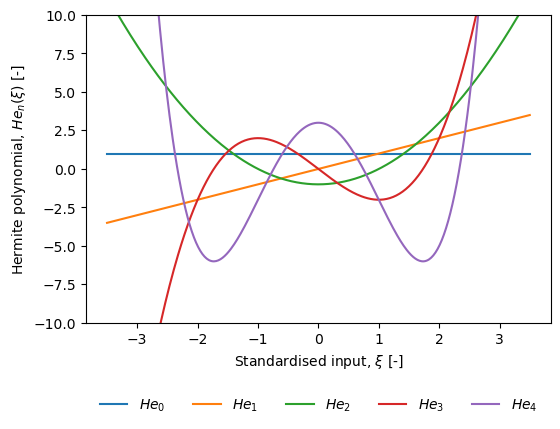

E[He_m He_n]:
[[ 1.  0. -0. -0.  0.]
 [ 0.  1.  0. -0.  0.]
 [-0. -0.  2. -0. -0.]
 [ 0. -0. -0.  6.  0.]
 [ 0. -0. -0.  0. 24.]]
n! = [1, 1, 2, 6, 24]


In [3]:
# A fine grid of standardised inputs for drawing the curves, xi [-].
xi_grid = np.linspace(-3.5, 3.5, 400)

# One figure for the five polynomials.
fig, ax = plt.subplots(figsize=(6.0, 4.0))
for n in range(5):
    # A coefficient vector with a single 1 in position n: hermeval then evaluates He_n alone.
    selector = np.zeros(n + 1)
    selector[n] = 1.0
    # Draw He_n(xi) on the grid.
    ax.plot(xi_grid, He.hermeval(xi_grid, selector), label="$He_%d$" % n)
# Axis labels with quantity, symbol and units; a y-range that keeps the low orders readable.
ax.set_xlabel(r"Standardised input, $\xi$ [-]")
ax.set_ylabel(r"Hermite polynomial, $He_n(\xi)$ [-]")
ax.set_ylim(-10, 10)
# Legend below the plot, so that it hides no curve.
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.2), frameon=False)
plt.show()

# Number of quadrature nodes n_q: 5 is enough here, since the products He_m He_n with m, n <= 4 have degree <= 8 <= 2 n_q - 1 = 9.
n_q = 5
# hermegauss(n_q) returns n_q nodes zeta_q and n_q raw weights w_q, with sum(w_q f(zeta_q)) = integral of f(xi) exp(-xi^2/2) dxi for polynomials f up to degree 2 n_q - 1.
nodes, weights = He.hermegauss(n_q)
# The raw weights add up to sqrt(2 pi); dividing by it restores the normal density's factor 1/sqrt(2 pi), so the weights add up to 1 and sum(p_q f(zeta_q)) = E[f(xi)].
weights = weights / np.sqrt(2.0 * np.pi)
# Row n of this array is He_n evaluated at the n_q nodes.
basis_at_nodes = np.array([He.hermeval(nodes, np.eye(5)[n]) for n in range(5)])
# E[He_m He_n] for all pairs at once: the weighted inner product of rows m and n, a 5 x 5 table.
gram = (basis_at_nodes * weights) @ basis_at_nodes.T
# Print the table and the factorials it should equal on its diagonal.
print("E[He_m He_n]:")
print(np.round(gram, 10))
print("n! =", [math.factorial(n) for n in range(5)])

The plot shows the pattern: $He_0$ is the constant 1, $He_1$ is a straight line, $He_2$ a parabola with its minimum of $-1$ at $\xi=0$, and each
higher polynomial bends once more, with $n$ zero crossings for degree $n$. They grow quickly outside $|\xi|\approx3$, which is rare for a standard normal input.

The table is the orthogonality check. Every off-diagonal entry is zero (a few print as $-0$, which is rounding), and the diagonal reads 1, 1, 2, 6, 24,
exactly $0!,1!,2!,3!,4!$. So the formula $\mathrm E[He_mHe_n]=n!\,\delta_{mn}$ holds for our numerical integration too. This makes the variance of an expansion a plain sum of squared coefficients, as Step 2 uses, and it keeps the fit well conditioned. For a finite random sample the average of $He_mHe_n$ over the sample points is close to zero but not exactly zero; Step 4 shows what that does to a fit.

### Step 2 &ndash; A first expansion with a known answer: $y=e^{\lambda\xi}$

The goal of this step is to **demonstrate an expansion on a test function that is simple enough for us to derive its exact coefficients by hand**. We choose

$$y=e^{\lambda\xi},$$

where the number $\lambda$ sets how strongly $y$ depends on $\xi$. With the exact answer in hand, we can see how much a truncated expansion loses, and later we can check our code against it.

How do we expand it? The Hermite polynomials have a **generating function**
([DLMF Eq. 18.12.16](https://dlmf.nist.gov/18.12)): a single exponential that contains all of them,

$$e^{\xi\lambda-\lambda^2/2}=\sum_{n=0}^{\infty}He_n(\xi)\,\frac{\lambda^n}{n!}.$$

This holds for every number $\lambda$: expanding the left side in powers of $\lambda$ gives $He_n(\xi)$ as the coefficient of $\lambda^n/n!$. Multiply both sides by $e^{\lambda^2/2}$ and the left side becomes our test function, and the right side its expansion:

$$e^{\lambda\xi}=\sum_{n=0}^{\infty}a_n\,He_n(\xi),\qquad a_n=e^{\lambda^2/2}\,\frac{\lambda^n}{n!}.$$

where $a_n$ is the coefficient of $He_n$.

**From the coefficients to the mean and the variance.** Orthogonality lets us read both statistics from the coefficients, with no further integration. Recall $He_0=1$, so $y=a_0+a_1He_1+a_2He_2+\dots$

*Mean.* $\mathrm E[y]=\sum_n a_n\mathrm E[He_n]$. Because $He_0=1$, we can write $\mathrm E[He_n]=\mathrm E[He_n\,He_0]=0!\,\delta_{n0}$ by orthogonality, so only $n=0$ survives:

$$\mathrm E[y]=a_0=e^{\lambda^2/2}.$$

*Variance.* $\mathrm{Var}[y]=\mathrm E\big[(y-\mathrm E[y])^2\big]$. Subtracting the mean removes the $n=0$ term, so $y-\mathrm E[y]=\sum_{n\ge1}a_n He_n$. Squaring gives a double sum, $\sum_m\sum_n a_ma_n\,\mathrm E[He_mHe_n]$, and orthogonality keeps only the terms with $m=n$:

$$\mathrm{Var}[y]=\sum_{n\ge1}a_n^2\,n!.$$

Inserting $a_n$ gives $a_n^2\,n!=e^{\lambda^2}\lambda^{2n}/n!$. The sum is the series $\sum_{n\ge0}x^n/n!=e^x$ with $x=\lambda^2$, missing its $n=0$ term, which is 1:

$$\mathrm{Var}[y]=e^{\lambda^2}\sum_{n\ge1}\frac{(\lambda^2)^n}{n!}=e^{\lambda^2}\big(e^{\lambda^2}-1\big).$$

Truncating at order $p$ keeps the terms $n\le p$ and drops the rest. The error this causes is easy to compute. The difference between $y$ and its truncation is $\sum_{n>p}a_nHe_n$, and by the same orthogonality argument as for the variance, its mean square is the variance carried by the dropped terms, $\sum_{n>p}a_n^2\,n!$. As a share of the total variance, this is the **share of variance lost**,

$$\frac{\sum_{n>p}a_n^2\,n!}{\mathrm{Var}[y]}.$$

It is the error that truncation alone causes, when the coefficients are exact.

Two cases will show the main point, one with a small and one with a large $\lambda$. For $\lambda=0.3$, $y$ changes by about 35% per standard deviation of $\xi$, so $y$
is nearly a straight line over the range of $\xi$: **weak curvature**. For $\lambda=1$, $y$ is **strongly curved**. The first cell below defines the functions we need: the formula for $a_n$ and the share of variance lost. The second tabulates and plots the loss for $p=1\dots4$.

In [4]:
def factorials(p):
    """Return the array [0!, 1!, ..., p!] as floats."""
    # One factorial per degree n = 0..p.
    return np.array([math.factorial(n) for n in range(p + 1)], dtype=float)


def exp_coefficients(lam, p):
    """Exact Hermite coefficients a_n = exp(lam^2/2) lam^n / n! of y = exp(lam xi), n = 0..p (generating function)."""
    # The degrees n = 0..p, and then the formula of the text for every n at once.
    n = np.arange(p + 1)
    return np.exp(lam ** 2 / 2.0) * lam ** n / factorials(p)


def lost_variance_share(lam, p):
    """Share of Var[exp(lam xi)] carried by the Hermite terms of order above p (what truncation drops)."""
    # The degrees n = 1..p that are kept, and their factorials n!.
    n = np.arange(1, p + 1)
    fact = factorials(p)[1:]
    # Variance of the kept terms: the sum of a_n^2 n! for n = 1..p.
    kept = np.sum((np.exp(lam ** 2 / 2.0) * lam ** n / fact) ** 2 * fact)
    # One minus the kept share of the exact total variance exp(lam^2) (exp(lam^2) - 1).
    return 1.0 - kept / (np.exp(lam ** 2) * (np.exp(lam ** 2) - 1.0))

With the functions defined, the next cell prints the table of variance lost for $p=1\dots4$ for both inputs, and plots it.


Share of the output variance lost by truncating at order p:
   p   lambda = 0.3   lambda = 1.0
   1      4.4325%      41.80%
   2      0.1320%      12.70%
   3      0.0030%       3.00%
   4      0.0001%       0.58%


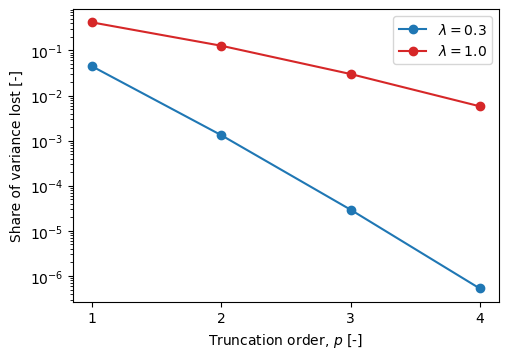

In [5]:
# The truncation orders p = 1..4 and the table of variance shares lost.
orders = np.arange(1, 5)
print("\nShare of the output variance lost by truncating at order p:")
print("   p   lambda = 0.3   lambda = 1.0")
# One table row per order: the share lost for lambda = 0.3 and for lambda = 1, in percent.
for p in orders:
    print("   %d   %9.4f%%  %9.2f%%" % (p, 100 * lost_variance_share(0.3, p), 100 * lost_variance_share(1.0, p)))

# The same numbers as a plot, on a logarithmic axis so that both cases are visible.
fig, ax = plt.subplots(figsize=(5.5, 3.8))
for lam, color in ((0.3, "C0"), (1.0, "C3")):
    ax.semilogy(orders, [lost_variance_share(lam, p) for p in orders], "o-", color=color, label=r"$\lambda=%.1f$" % lam)
# Axis labels and legend.
ax.set_xlabel(r"Truncation order, $p$ [-]")
ax.set_ylabel("Share of variance lost [-]")
ax.set_xticks(orders)
# Legend naming the two inputs, then show the figure.
ax.legend()
plt.show()

The table answers the question of how many orders are needed. For $\lambda=0.3$ (weak curvature), a straight line ($p=1$) already carries all but 4.4% of the variance, and two orders leave 0.13%.
For $\lambda=1$ (strong curvature), a straight line misses 41.8% of the variance: the output is strongly curved over the spread of $\xi$. It takes $p=3$ to get below 5% (3.0% lost)
and $p=4$ to get below 1% (0.58% lost). On the log axis each curve is close to a straight line, which means the loss shrinks by a roughly fixed factor per order: 30 to 50 times
for $\lambda=0.3$, only 3 to 5 times for $\lambda=1$. How many orders you need therefore depends on how nonlinear the output is over the spread of the input. The number of inputs then decides how many terms each order costs (Step 3).

### Step 3 &ndash; Two inputs: interaction terms and the number of terms

With two inputs, $\xi_1$ and $\xi_2$, we consider the test function $y=e^{\lambda_1\xi_1+\lambda_2\xi_2}$, with one strength $\lambda$ per input. Its expansion follows from Step 2, because a sum in the exponent is a product of exponentials:

$$y=e^{\lambda_1\xi_1}\,e^{\lambda_2\xi_2}.$$

Each factor depends on one input only, so each has its own one-input expansion from Step 2:

$$e^{\lambda_1\xi_1}=\sum_{i=0}^{\infty}a^{(1)}_i\,He_i(\xi_1),\quad a^{(1)}_i=e^{\lambda_1^2/2}\frac{\lambda_1^i}{i!};\qquad
e^{\lambda_2\xi_2}=\sum_{j=0}^{\infty}a^{(2)}_j\,He_j(\xi_2),\quad a^{(2)}_j=e^{\lambda_2^2/2}\frac{\lambda_2^j}{j!}.$$

Multiplying the two sums term by term gives every pair of degrees $(i,j)$ exactly once:

$$y=\sum_{i=0}^{\infty}\sum_{j=0}^{\infty}a^{(1)}_i\,a^{(2)}_j\,He_i(\xi_1)\,He_j(\xi_2)=\sum_{i,j}a_{ij}\,He_i(\xi_1)\,He_j(\xi_2),\qquad a_{ij}=e^{(\lambda_1^2+\lambda_2^2)/2}\,\frac{\lambda_1^i\,\lambda_2^j}{i!\,j!}.$$

where the superscript of $a^{(1)}_i$ and $a^{(2)}_j$ says which input the coefficient belongs to, $i$ and $j$ are the polynomial degrees in $\xi_1$ and $\xi_2$, and $a_{ij}$ is the coefficient of the product $He_i(\xi_1)\,He_j(\xi_2)$.
The basis functions are products of one-input polynomials. The terms with both $i>0$ and $j>0$ are **interaction terms**: they describe how the effect of one input changes with the other.

**Which terms appear?** Let's keep the pairs with $i+j\le2$. These are six terms. Note that the exponential term in $a_{ij}$ does not depend on $i$ or $j$, and for $i=j=0$ the rest of the formula equals 1, so this common factor is the coefficient of the constant term, $a_{00}=e^{(\lambda_1^2+\lambda_2^2)/2}$ (which is also the mean of $y$, as in Step 2). Writing every coefficient as $a_{00}$ times what is left, $a_{ij}=a_{00}\,\lambda_1^i\lambda_2^j/(i!\,j!)$, gives:

| $(i,j)$ | term | coefficient $a_{ij}$ |
|---|---|---|
| $(0,0)$ | $1$ | $a_{00}$ |
| $(1,0)$ | $He_1(\xi_1)=\xi_1$ | $a_{00}\,\lambda_1$ |
| $(0,1)$ | $He_1(\xi_2)=\xi_2$ | $a_{00}\,\lambda_2$ |
| $(2,0)$ | $He_2(\xi_1)=\xi_1^2-1$ | $a_{00}\,\lambda_1^2/2$ |
| $(1,1)$ | $He_1(\xi_1)\,He_1(\xi_2)=\xi_1\xi_2$ (interaction) | $a_{00}\,\lambda_1\lambda_2$ |
| $(0,2)$ | $He_2(\xi_2)=\xi_2^2-1$ | $a_{00}\,\lambda_2^2/2$ |

**Orthogonality carries over.** The two inputs are independent, so the average of a product of a function of $\xi_1$ and a function of $\xi_2$ is the product of the two averages. Therefore

$$\mathrm E\big[He_i(\xi_1)He_j(\xi_2)\;He_{i'}(\xi_1)He_{j'}(\xi_2)\big]=\mathrm E\big[He_iHe_{i'}\big]\,\mathrm E\big[He_jHe_{j'}\big]=i!\,j!\;\delta_{ii'}\delta_{jj'}.$$

Two different terms are orthogonal, and the mean square of a term is $i!\,j!$. With $d$ inputs nothing new happens: the pair $(i,j)$ becomes a list of $d$ degrees, each term is a product of $d$ one-input polynomials, and its mean square is a product of $d$ factorials.

To keep the number of terms from exploding when $d$ is large, we use the **total-order** truncation of Thapa et al. (2021) and
[Hosder et al. (2010)](https://doi.org/10.2514/1.39389): keep every term whose degrees add up to at most $p$,

$$\boldsymbol\alpha=(\alpha_1,\dots,\alpha_d):\quad \alpha_1+\dots+\alpha_d\le p,\qquad
\psi_{\boldsymbol\alpha}(\boldsymbol\xi)=\prod_{k=1}^{d}He_{\alpha_k}(\xi_k).$$

where $\alpha_1,\dots,\alpha_d$ are the degrees used for inputs $1,\dots,d$ ($\alpha_k$ for input $k$), $\boldsymbol\alpha$ is the **multi-index** that lists them, $d$ is the number of inputs,
and $\psi_{\boldsymbol\alpha}$ is the basis polynomial for that multi-index.

The expansion of an output $y$ in $d$ inputs is then

$$y(\boldsymbol\xi)\approx\sum_{j=0}^{P}a_j\,\psi_j(\boldsymbol\xi),$$

where the sum runs over the multi-indices with $\alpha_1+\dots+\alpha_d\le p$. We number them $0,1,\dots,P$ in the order the code lists them, so that $P+1$ is their count, $\psi_j$ is $\psi_{\boldsymbol\alpha}$ for the $j$-th multi-index, and $a_j$ is its coefficient (in the units of $y$). The number of terms is a binomial coefficient,

$$P+1=\binom{p+d}{d}=\frac{(p+d)!}{p!\,d!}.$$

Do not confuse the two letters. $p$ is the **order**: the largest total degree we keep, which we choose. $P$ is the **index of the last term**, so the expansion has $P+1$ terms, and it depends on both $p$ and $d$. For example, with $d=2$ and $p=2$ the six terms of the table above are numbered $j=0,\dots,5$, so $P=5$.

The next cell defines the functions the rest of the notebook uses: the list of multi-indices (built with `itertools`),
the **design matrix** that evaluates every basis polynomial at every sample, the squared norms $\mathrm E[\psi_{\boldsymbol\alpha}^2]=\prod_k\alpha_k!$
that follow from orthogonality, and the exact two-input coefficients.

In [6]:
def total_order_indices(d, p):
    """All multi-indices alpha with sum(alpha) <= p for d inputs.

    Returns an integer array of shape (P+1, d), ordered by total degree, the constant term first.
    """
    rows = []
    # Loop over the total degree, 0..p.
    for degree in range(p + 1):
        # A combination (with repeats) of `degree` input numbers: input k appearing m times means alpha_k = m.
        for combo in itertools.combinations_with_replacement(range(d), degree):
            # Count how often each input appears; the constant term (degree 0) is the zero vector.
            rows.append(np.bincount(combo, minlength=d) if degree > 0 else np.zeros(d, dtype=int))
    indices = np.array(rows)
    # Sanity check: the enumeration must give as many multi-indices as the binomial formula (p+d)!/(p! d!).
    assert len(indices) == math.comb(p + d, d)
    return indices


def design_matrix(xi, alphas):
    """Evaluate every basis polynomial at every sample.

    Parameters
    ----------
    xi : (n, d) array
        Standardised inputs, one row per sample [-].
    alphas : (P+1, d) integer array
        Multi-indices, one row per basis polynomial.

    Returns
    -------
    (n, P+1) array
        Psi[i, j] = prod_k He_{alphas[j, k]}(xi[i, k]).
    """
    n, d = xi.shape
    # The highest degree needed, and He_m(xi[i, k]) for every degree m up to it (hermevander): shape (n, d, p_max+1).
    p_max = alphas.max()
    he = He.hermevander(xi, p_max)
    # Start from ones, then multiply in one factor He_{alpha_k}(xi_k) per input.
    psi = np.ones((n, len(alphas)))
    for j, alpha in enumerate(alphas):
        for k in range(d):
            psi[:, j] *= he[:, k, alpha[k]]
    return psi


def basis_norms(alphas):
    """E[psi_alpha^2] = prod_k alpha_k! for every multi-index (orthogonality of the He_n)."""
    # The product of the factorials of the degrees, one value per multi-index.
    return np.array([np.prod([math.factorial(m) for m in alpha]) for alpha in alphas], dtype=float)


def exp2_coefficients(lam1, lam2, alphas):
    """Exact coefficients a_ij = exp((lam1^2+lam2^2)/2) lam1^i lam2^j / (i! j!) of y = exp(lam1 xi_1 + lam2 xi_2), per multi-index."""
    # The degrees in xi_1 and xi_2 for every multi-index, then the formula of the text.
    i, j = alphas[:, 0], alphas[:, 1]
    return (np.exp((lam1 ** 2 + lam2 ** 2) / 2.0) * lam1 ** i * lam2 ** j
            / np.array([math.factorial(m) * math.factorial(n) for m, n in zip(i, j)]))

The following cell counts the terms of the total-order expansion, that is, the number $P+1$ of basis polynomials $\psi_j$ that are kept, with the binomial formula, for orders $p=1,\dots,4$ and for three numbers of inputs: $d=2$ (our toy model), $d=11$ (the eleven ply properties of Thapa et al.) and $d=15$ (the uncertain ply properties of our own model, listed in NB8).
It also prints the six multi-indices of the toy model at $p=2$, built by `total_order_indices`, which are the six terms of the table above. That function checks its own count against the binomial formula before it returns.

In [7]:
# Header of the table of term counts.
print("Number of terms P+1 = (p+d)!/(p! d!):")
print("   d \\ p " + "".join("%8d" % p for p in range(1, 5)))
# One row per number of inputs d: the toy model, Thapa et al., and our model.
for d, who in ((2, "toy model"), (11, "Thapa et al."), (15, "this notebook")):
    # The number of terms for p = 1..4, from the binomial coefficient (p+d)!/(p! d!).
    counts = []
    for p in range(1, 5):
        counts.append(math.comb(p + d, d))
    # Print the row, with its label.
    print("  %3d     " % d + "".join("%8d" % c for c in counts) + "   (%s)" % who)
# The six multi-indices of the two-input toy model at order 2.
print("\nd = 2, p = 2 multi-indices (degree in xi_1, degree in xi_2):")
print(total_order_indices(2, 2).tolist())

Number of terms P+1 = (p+d)!/(p! d!):
   d \ p        1       2       3       4
    2            3       6      10      15   (toy model)
   11           12      78     364    1365   (Thapa et al.)
   15           16     136     816    3876   (this notebook)

d = 2, p = 2 multi-indices (degree in xi_1, degree in xi_2):
[[0, 0], [1, 0], [0, 1], [2, 0], [1, 1], [0, 2]]


For two inputs the terms are 3, 6, 10 and 15 at orders 1 to 4. The list for $p=2$ shows what the six terms are: the constant $(0,0)$, one linear term per input $(1,0)$ and $(0,1)$, one square per input $(2,0)$ and $(0,2)$,
and one interaction $(1,1)$.

The growth with the number of inputs is the main cost of the method. At order 1 there are only $d+1$ terms: 12 for Thapa et al.'s 11 inputs and 16 for our 15. At order 2 they are 78 and 136, at order 3
364 and 816, and at order 4 already 1,365 and 3,876. [NB8](08_pce_surrogate_open_hole_tension.ipynb) turns these counts into a number of Abaqus runs. The values for $d=11$, 78 at order 2 and 364 at order 3, are the ones to set beside the 306 and 498 runs of Thapa et al.'s Table 3.

### Step 4 &ndash; Finding the coefficients from random runs

In a real problem the coefficients are unknown and all we have is a limited number of model runs. This step shows how to get the coefficients from those runs and how to judge the result; Step 5 then tries both on the two-input toy model, whose exact coefficients we know. The method to calculate the coefficients is called **point collocation** (Hosder et al., 2010; Thapa et al., 2021). Draw $n_s$ random points $\boldsymbol\xi^{(1)},\dots,\boldsymbol\xi^{(n_s)}$, run the model at each to get $y^{(1)},\dots,y^{(n_s)}$, and choose the coefficients so that the truncated polynomial matches those outputs as closely as possible. Collect the basis polynomials evaluated at the samples in the **design matrix** $\Psi_{ij}=\psi_j(\boldsymbol\xi^{(i)})$ (one row per sample, one column per term). The coefficients then solve the least-squares problem

$$\Psi\,\hat{\mathbf a}\approx\mathbf y,\qquad \hat{\mathbf a}=\arg\min_{\mathbf a}\ \lVert\Psi\mathbf a-\mathbf y\rVert^2 .$$

where $\hat{\mathbf a}$ is the vector of fitted coefficients and $\mathbf y$ the vector of $n_s$ run outputs. Thapa et al. write the
solution as $(\Psi^T\Psi)^{-1}\Psi^T\mathbf y$; in the code we call `numpy.linalg.lstsq`, which solves the same problem more stably than forming that inverse.

**Why orthogonality matters for the fit.** In Step 1, "orthogonal" meant that the *expected value* of a product of two basis polynomials is zero: an average over the whole normal distribution. The fit never sees that distribution. It sees only the $n_s$ random points we take, so it works with the average over those points.

To see where that average enters, look at the **normal equations** satisfied by the least-squares solution, $\Psi^T\Psi\,\hat{\mathbf a}=\Psi^T\mathbf y$. Column $i$ of $\Psi$ lists $\psi_i$ at every sample point. Entry $(i,j)$ of $\Psi^T\Psi$ is the dot product of columns $i$ and $j$: multiply the two polynomials at each point, then add over the points,

$$(\Psi^T\Psi)_{ij}=\sum_{k=1}^{n_s}\psi_i(\boldsymbol\xi^{(k)})\,\psi_j(\boldsymbol\xi^{(k)}).$$

A sum of $n_s$ values is $n_s$ times their average, so

$$\frac{1}{n_s}(\Psi^T\Psi)_{ij}=\overline{\psi_i\psi_j},$$

where the bar is the average over the sample points. This is the sample version of $\mathrm E[\psi_i\psi_j]$ from Step 1.

- If $\overline{\psi_i\psi_j}$ were exactly zero for $i\neq j$, $\Psi^T\Psi$ would be diagonal and every coefficient would be fitted independently of the others.
- For random points it is close to zero but not exactly zero. So $\Psi^T\Psi$ has small off-diagonal entries and the coefficients are slightly coupled: part of what one polynomial should explain is credited to another. More points bring the averages closer to their expectations.

How large should $n_s$ be? We need at least $P+1$ runs of the model, the number of unknowns, but, since we are solving a least-squares problem, we actually need more samples than unknowns. Hosder et al. define the **oversampling ratio** $n_p=n_s/(P+1)$. In an earlier study of their own they tried $n_p=1$ to 4 and report that $n_p=2$ gave a better approximation of the statistics than the minimum, $n_p=1$, at every polynomial degree. More runs improve the fit, but each one is a model run, so $n_p=2$ is a natural compromise. In Step 5 we test this the trade-off on the toy model.

How do we judge the result? On $n_V$ fresh samples that were *not* used for the fit, we compare the true output with
the prediction $\tilde y$ through the **relative mean-square error**

$$\varepsilon=\frac{\sum_{i=1}^{n_V}\big(y^{(i)}-\tilde y^{(i)}\big)^2}{\sum_{i=1}^{n_V}\big(y^{(i)}-\bar y\big)^2}$$

where $\bar y$ is the mean of the $n_V$ true outputs (Thapa et al., 2021). $\varepsilon=0$ is a perfect fit and
$\varepsilon=1$ is no better than always predicting the mean. If the coefficients were exact, the only error would be the truncation, and $\varepsilon$ would equal the share of variance lost from Step 2. That share is therefore the lowest $\varepsilon$ an order-$p$ expansion can reach, and any excess is the cost of estimating the coefficients from few runs.

> **Pitfall:** Thapa et al. call this quantity "RMSE". No square root is taken: it is a *mean-square* error, made
> relative to the output's own spread.

### Step 5 &ndash; How good is the fit, and how many runs does it need?

Now we try the recipe on a model whose exact coefficients we know: the toy model
$y=e^{\lambda_1\xi_1+\lambda_2\xi_2}$ with $\lambda_1=1$ and $\lambda_2=0.5$, so $y$ is more strongly curved
in $\xi_1$ than in $\xi_2$. We chose it on purpose as a *difficult* case, so that the details of the method
show: over the spread of the inputs it is strongly curved, far from a low-degree polynomial. A model closer
to a low-degree polynomial would make every step below easier, but for a real model we only find out how
close it is by fitting and validating.

Before fitting anything, let's look at the problem. The next cell sets the constants of the demonstration,
defines the functions the steps below need (the toy model, $\varepsilon$, the least-squares fit and the exact
truncation loss) and draws a **reference set** of 200,000 random inputs to evaluate the reference output distribution. Note that only a model that costs nothing to evaluate can afford a set that large, so this preliminary step is typically not completely available in real cases.

In [8]:
# The toy model's strengths: y depends more steeply on xi_1 (lam1) than on xi_2 (lam2), y = exp(lam1 xi_1 + lam2 xi_2).
LAM_1, LAM_2 = 1.0, 0.5
# The orders compared below, the oversampling ratio n_p = n_s/(P+1) used for that comparison, and the order up
# to which we compute exact coefficients (far beyond what matters, for the truncation loss).
ORDERS = (1, 2, 3, 4)
N_P_SWEEP = 5
P_EXACT = 12
# Seeds of the training points, of the reference set and of the repeated validation sets (the Abaqus design seeds, 7 and 8, are in NB8).
SEED_TRAIN, SEED_VALID, SEED_VALID_SETS = 11, 12, 13
# Size of the reference set, and the validation points one campaign can afford (the plate's 100 runs, NB8).
N_VALID_TOY = 200_000
N_VALID = 100


def toy_output(xi):
    """The toy model y = exp(lam1 xi_1 + lam2 xi_2), evaluated at every row of xi (n, 2)."""
    # One exponential per sample.
    return np.exp(LAM_1 * xi[:, 0] + LAM_2 * xi[:, 1])


def relative_mse(y_true, y_pred):
    """Relative mean-square error epsilon, Thapa et al. Eq. (34)."""
    # Squared error of the prediction over the squared spread of the true values around their mean.
    return np.sum((y_true - y_pred) ** 2) / np.sum((y_true - y_true.mean()) ** 2)


def fit_pce(xi, y, alphas):
    """Least-squares PCE coefficients from samples (xi, y): solves Psi a = y, Thapa et al. Eqs. (26)-(27)."""
    # lstsq returns the coefficients first; the other return values (residuals, rank, singular values) are not needed.
    coeffs, *_ = np.linalg.lstsq(design_matrix(xi, alphas), y, rcond=None)
    return coeffs


def exact_truncation_loss(p, alphas_all, a_all, norms_all):
    """Variance share carried by every term of total degree above p, from the exact coefficients."""
    # The total degree of every multi-index, and the variance each term carries, a^2 E[psi^2].
    degree = alphas_all.sum(axis=1)
    variance = a_all ** 2 * norms_all
    # Dropped variance over total variance (the constant term carries none).
    return np.sum(variance[degree > p]) / np.sum(variance[degree > 0])


# The reference set, drawn once and never used for fitting, and the toy model's output at its points.
xi_toy_valid = np.random.default_rng(SEED_VALID).standard_normal((N_VALID_TOY, 2))
y_toy_valid = toy_output(xi_toy_valid)

**A look at the toy model.** The next cell draws three panels. On the left, the toy model as a contour map of $y$ over the plane of the two inputs, with the 1, 2 and 3 standard-deviation circles of the input distribution dashed. In the middle, the 200,000 points of the reference set. On the right, a histogram of $y$ at those points, with the exact median and mean of $y$ marked. Both come from formulas, not from the points: the median is $e^0=1$, because the exponent is symmetric about zero, and the mean is $e^{(\lambda_1^2+\lambda_2^2)/2}$, as in Step 2.

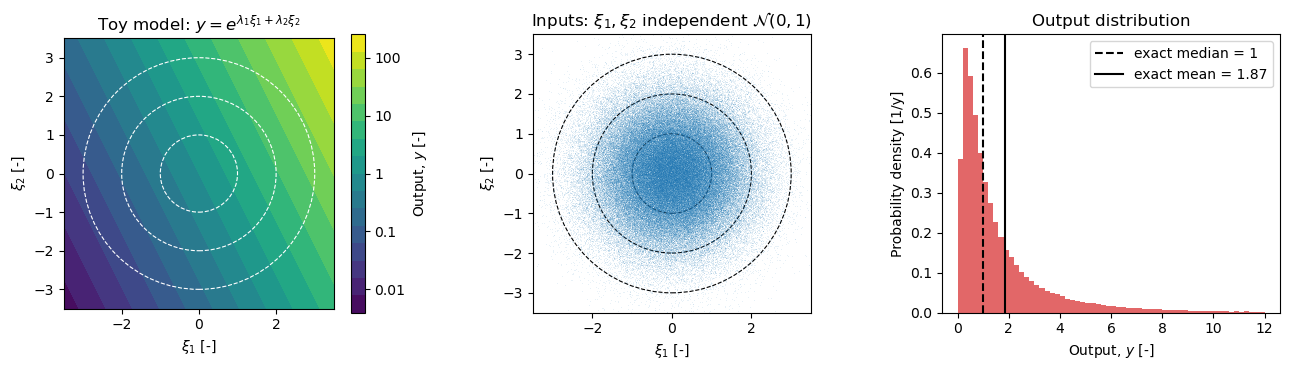

Share of the reference outputs above 12: 1.29%


In [9]:
from matplotlib.colors import LogNorm

# Plot range of the inputs (3.5 standard deviations), and the output value at which the histogram is cut for readability.
XI_MAX, Y_MAX = 3.5, 12
# A grid of the two standardised inputs and the toy model on it, for the contour map.
grid_1, grid_2 = np.meshgrid(np.linspace(-XI_MAX, XI_MAX, 200), np.linspace(-XI_MAX, XI_MAX, 200))
y_map = np.exp(LAM_1 * grid_1 + LAM_2 * grid_2)

fig, (ax_map, ax_in, ax_out) = plt.subplots(1, 3, figsize=(13, 3.8))
# Left: y on a logarithmic colour scale, with bands of a factor of two, because y spans orders of magnitude.
cs = ax_map.contourf(grid_1, grid_2, y_map, levels=2.0 ** np.arange(-8, 9), norm=LogNorm(), cmap="viridis")
fig.colorbar(cs, ax=ax_map, label=r"Output, $y$ [-]", ticks=[0.01, 0.1, 1, 10, 100], format="%g")
ax_map.set_title(r"Toy model: $y=e^{\lambda_1\xi_1+\lambda_2\xi_2}$")
# Middle: the reference points, one pixel each and translucent, so that their density shows.
ax_in.plot(xi_toy_valid[:, 0], xi_toy_valid[:, 1], ",", color="C0", alpha=0.1, rasterized=True)
ax_in.set_title(r"Inputs: $\xi_1,\xi_2$ independent $\mathcal{N}(0,1)$")
# Both input-plane panels: circles of radius 1, 2 and 3 standard deviations, the same axis limits, labels and equal scales.
for ax, colour in ((ax_map, "w"), (ax_in, "k")):
    for radius in (1, 2, 3):
        ax.add_patch(plt.Circle((0, 0), radius, fill=False, ls="--", lw=0.8, color=colour))
    ax.set(xlim=(-XI_MAX, XI_MAX), ylim=(-XI_MAX, XI_MAX), aspect="equal", xlabel=r"$\xi_1$ [-]", ylabel=r"$\xi_2$ [-]")
# Right: histogram of the output at the reference points, with the exact median (exponent symmetric about 0, so e^0 = 1) and exact mean.
y_mean = np.exp((LAM_1 ** 2 + LAM_2 ** 2) / 2)
ax_out.hist(y_toy_valid, bins=np.linspace(0, Y_MAX, 61), density=True, color="C3", alpha=0.7)
ax_out.axvline(1.0, color="k", ls="--", label="exact median = 1")
ax_out.axvline(y_mean, color="k", ls="-", label="exact mean = %.2f" % y_mean)
# Labels and legend of the output panel.
ax_out.set(xlabel=r"Output, $y$ [-]", ylabel="Probability density [1/y]", title="Output distribution")
ax_out.legend()
fig.tight_layout()
plt.show()
# How much of the output lies beyond the histogram's range.
print("Share of the reference outputs above %g: %.2f%%" % (Y_MAX, 100 * np.mean(y_toy_valid > Y_MAX)))

On the contour map, $y$ grows towards the upper right, faster along $\xi_1$ than along $\xi_2$ because $\lambda_1>\lambda_2$. The colour bands are straight lines, since the exponent is a linear function of the inputs, and each band is a factor of two in $y$. Over the range of the inputs, $y$ spans orders of magnitude: at $(\xi_1,\xi_2)=(3,0)$ it is $e^3\approx20$, and at $(-3,0)$ it is $e^{-3}\approx0.05$. In the middle, the reference points are symmetric about zero, densest at the centre, and few lie beyond the 3-standard-deviation circle.

On the right, the exponential turns that symmetric input into a lopsided output. Most outputs pile up at small values and a few are many times larger: the median of 1 lies left of the mean of 1.87, because a few large outputs pull the mean up. About 1.3% of the outputs exceed 12 and are not drawn. The negative side of the inputs is squeezed towards 0, since $y$ cannot go below 0, and the positive side is stretched. This is called a **heavy upper tail**.

**What we are going to do.** For each order $p=1,\dots,4$ we:

1. draw $n_s=n_p(P+1)$ random training points, evaluate the toy model at them and fit the coefficients by
   least squares;
2. compute $\varepsilon$ on 100 validation points (same number used by Thapa et al., 2021);
3. compare $\varepsilon$ with the exact truncation loss, the lowest $\varepsilon$ this order can reach;
4. compare the fitted coefficients with the exact ones.

Two choices before we start. The oversampling ratio is fixed at $n_p=5$ for all four orders: with five times as many runs as unknowns the fit is well determined, so what the
comparison between the orders shows is the truncation and not the scatter of the fit. And each order gets **one** draw of training points, not an average over many, because a real campaign has one design and one fit.

The next cell computes the exact coefficients up to order 12, which the truncation loss needs, then runs the four fits and prints one table row per order.

In [10]:
# Exact coefficients up to order P_EXACT: for the truncation loss and for comparison with the fits.
alphas_all = total_order_indices(2, P_EXACT)
a_all, norms_all = exp2_coefficients(LAM_1, LAM_2, alphas_all), basis_norms(alphas_all)

# One random stream for the training points of all four orders.
rng_train = np.random.default_rng(SEED_TRAIN)
results = []
print("   p   P+1   n_s   eps (%d validation points)   eps (exact truncation)" % N_VALID)
for p in ORDERS:
    # The basis, its number of terms P+1, and the training size n_s = n_p (P+1).
    alphas = total_order_indices(2, p)
    n_terms = len(alphas)
    n_s = N_P_SWEEP * n_terms
    # Draw the training points, run the toy model at them and fit.
    xi_train = rng_train.standard_normal((n_s, 2))
    a_hat = fit_pce(xi_train, toy_output(xi_train), alphas)
    # Epsilon of the fit on the first N_VALID points of the reference set.
    eps = relative_mse(y_toy_valid[:N_VALID], design_matrix(xi_toy_valid[:N_VALID], alphas) @ a_hat)
    # The exact truncation loss, and the exact coefficients of the kept terms.
    eps_trunc = exact_truncation_loss(p, alphas_all, a_all, norms_all)
    a_exact = exp2_coefficients(LAM_1, LAM_2, alphas)
    # Keep everything for the checks below, and print one table row.
    results.append((p, n_terms, n_s, eps, eps_trunc, a_hat, a_exact, alphas))
    print("   %d   %3d   %3d   %25.4f   %22.4f" % (p, n_terms, n_s, eps, eps_trunc))

   p   P+1   n_s   eps (100 validation points)   eps (exact truncation)
   1     3    15                      0.4055                   0.4981
   2     6    30                      0.1765                   0.1843
   3    10    50                      0.0135                   0.0536
   4    15    75                      0.0054                   0.0128


$\varepsilon$ falls steeply with the order, from 0.41 at $p=1$ to 0.0054 at $p=4$, so each added order
improves the fit. Now compare each value with the exact truncation loss beside it, the lowest $\varepsilon$
that order can reach: 0.4055 against 0.4981, 0.1765 against 0.1843, 0.0135 against 0.0536, and 0.0054 against
0.0128. Every one of the four is **below** its own floor.

That cannot be. The floor is what is left when the coefficients are exact, so no fit of that order can do
better. The fault is not in the fits but in how we measured them: $\varepsilon$ is itself an estimate. It is a
ratio of sums over $n_V$ random points, so with few points it scatters like any sample average, and, as the
next cell shows, it is not even centred on the right value.

The next cell keeps the fits of the lowest and the highest order, $p=1$ and $p=4$, exactly as they are. It
recomputes $\varepsilon$ on fresh validation sets of 25 to 100,000 points, 200 sets of each size, and prints
the median, the 10th-to-90th percentile range and how often the result falls below the floor. The figure
shows the same against the value measured on all 200,000 reference points.

p = 1 (n_s = 15): eps on all 200000 reference points = 0.6292, exact truncation = 0.4981, squared error from the far 1% = 43%
      n_V   eps: 10th pct   median   90th pct   below the truncation loss
       25         0.2528    0.4509     0.7105                       62%
       50         0.3116    0.5028     0.6787                       48%
      100         0.3667    0.4940     0.6752                       50%
      200         0.4326    0.5718     0.7542                       24%
     1000         0.5242    0.5957     0.7020                        4%


    10000         0.5941    0.6330     0.6821                        0%


   100000         0.6200    0.6348     0.6559                        0%
p = 4 (n_s = 75): eps on all 200000 reference points = 0.0150, exact truncation = 0.0128, squared error from the far 1% = 79%
      n_V   eps: 10th pct   median   90th pct   below the truncation loss
       25         0.0019    0.0049     0.0198                       84%
       50         0.0018    0.0048     0.0229                       80%
      100         0.0028    0.0055     0.0200                       80%
      200         0.0026    0.0057     0.0175                       84%
     1000         0.0051    0.0091     0.0253                       70%


    10000         0.0083    0.0132     0.0235                       46%


   100000         0.0125    0.0156     0.0250                       16%


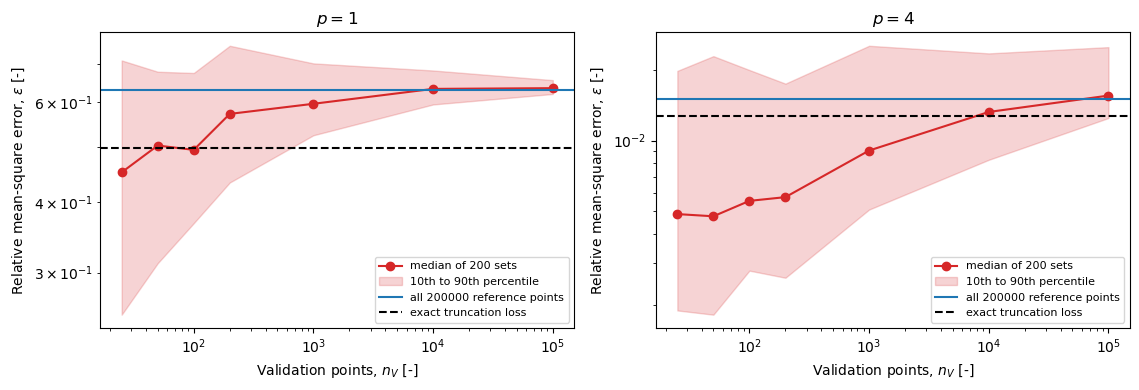

In [11]:
# The validation-set sizes to compare, how many fresh sets of each size, and one stream to draw them all
# (independent of the reference set and of the training points).
N_VALID_SIZES = (25, 50, 100, 200, 1_000, 10_000, 100_000)
N_SETS = 200
rng_valid = np.random.default_rng(SEED_VALID_SETS)
# "Far from the centre": the 1% of reference points with the largest distance from the origin of the input plane.
dist2 = (xi_toy_valid ** 2).sum(axis=1)
far = dist2 >= np.quantile(dist2, 0.99)

# One panel for the lowest order and one for the highest.
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.0))
for ax, p in zip(axes, (ORDERS[0], ORDERS[-1])):
    # This order's fit from the table above, and its epsilon on all the reference points (the best value we can get).
    _, _, n_s, _, eps_trunc, a_hat, _, alphas = results[p - 1]
    err2 = (y_toy_valid - design_matrix(xi_toy_valid, alphas) @ a_hat) ** 2
    eps_ref = err2.sum() / np.sum((y_toy_valid - y_toy_valid.mean()) ** 2)
    # Header of this order's table: its reference epsilon, its floor, and where its squared error sits.
    print("p = %d (n_s = %d): eps on all %d reference points = %.4f, exact truncation = %.4f, squared error from the far 1%% = %.0f%%"
          % (p, n_s, N_VALID_TOY, eps_ref, eps_trunc, 100 * err2[far].sum() / err2.sum()))
    print("      n_V   eps: 10th pct   median   90th pct   below the truncation loss")
    bands = []
    for n_v in N_VALID_SIZES:
        # N_SETS fresh validation sets of this size, each giving its own epsilon.
        eps_sets = np.empty(N_SETS)
        for s in range(N_SETS):
            xi_set = rng_valid.standard_normal((n_v, 2))
            eps_sets[s] = relative_mse(toy_output(xi_set), design_matrix(xi_set, alphas) @ a_hat)
        # The 10th, 50th and 90th percentile of those epsilons, and how often they fall below the floor.
        bands.append(np.percentile(eps_sets, [10, 50, 90]))
        print("   %6d   %12.4f  %8.4f  %9.4f   %22.0f%%" % (n_v, *bands[-1], 100 * np.mean(eps_sets < eps_trunc)))
    # The median with its 10th-to-90th percentile band, the reference value and the floor.
    bands = np.array(bands)
    ax.loglog(N_VALID_SIZES, bands[:, 1], "o-", color="C3", label="median of %d sets" % N_SETS)
    ax.fill_between(N_VALID_SIZES, bands[:, 0], bands[:, 2], color="C3", alpha=0.2, label="10th to 90th percentile")
    ax.axhline(eps_ref, color="C0", label="all %d reference points" % N_VALID_TOY)
    ax.axhline(eps_trunc, color="k", ls="--", label="exact truncation loss")
    # Labels and legend of this panel.
    ax.set(xlabel=r"Validation points, $n_V$ [-]", ylabel=r"Relative mean-square error, $\varepsilon$ [-]",
           title="$p=%d$" % p)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Both panels tell the same story: the more validation points, the higher $\varepsilon$ comes out, until it
settles at the value measured on the whole reference set (the blue line).

At $p=1$ the median is 0.45 from 25 points, below the floor of 0.4981, and crosses the floor between 100 and
200 points; it reaches the reference value of 0.6292 at about 10,000 points. The share of sets below the floor
drops from 62% at 25 points to 4% at 1,000 and none at 10,000. At $p=4$ the curve is shifted far to the
right: the median is 0.0055 from 100 points, barely a third of the reference 0.0150, and still 0.0091 from
1,000; only at 100,000 does it reach 0.0156. Eight sets of 100 points in ten fall below the floor, and even
with 10,000 points nearly one in two does.

The band tells the other half: from 100 points the middle 80% of the results span 0.37 to 0.68 at $p=1$ and
0.0028 to 0.0200 at $p=4$, factors of 2 and 7. A small validation set gives not only a biased $\varepsilon$
but a coarse one.

Why does a small set read low? A truncated polynomial matches the model well near the centre of the input
distribution, where most points fall, and worst far from it, where the dropped high-degree terms are large.
The printout shows this: the 1% of reference points farthest from the origin carry 43% of the squared error
at $p=1$ and 79% of it at $p=4$. A set of 100 points contains at least one of them only with probability
$1-0.99^{100}\approx63\%$, and a set of 25 only 22%. So a small validation set usually misses the corner of
the input space where the fit is bad, and the higher the order, the rarer the points that carry the error.

In practice we cannot cure this with more validation points: each one is a model run that
costs solver time. We must work with the number we can afford and read the $\varepsilon$
we obtain with caution.

With the measure understood, the next cell computes $\varepsilon$ for all four fits on the whole reference set, where it is practically free of noise. We can afford 200,000 points only because the toy model costs nothing.

In [12]:
# Epsilon of all four fits on the whole reference set, where it is practically free of noise.
print("   p   n_s   eps (%d reference points)   eps (exact truncation)   ratio" % N_VALID_TOY)
for p, n_terms, n_s, eps_small, eps_trunc, a_hat, a_exact, alphas in results:
    # This order's epsilon on every reference point, and how far above its floor it sits.
    eps_ref = relative_mse(y_toy_valid, design_matrix(xi_toy_valid, alphas) @ a_hat)
    print("   %d   %3d   %24.4f   %22.4f   %5.2f" % (p, n_s, eps_ref, eps_trunc, eps_ref / eps_trunc))

   p   n_s   eps (200000 reference points)   eps (exact truncation)   ratio
   1    15                     0.6292                   0.4981    1.26
   2    30                     0.2348                   0.1843    1.27
   3    50                     0.0886                   0.0536    1.65
   4    75                     0.0150                   0.0128    1.17


Now every $\varepsilon$ sits above its own floor, by a factor of 1.26, 1.27, 1.65 and 1.17. That excess is
the price of fitting the coefficients from $n_s$ random runs instead of knowing them exactly: with $n_p=5$ it
costs between 17% and 65% more error than the truncation alone.

Set that against what the order does. $\varepsilon$ falls from 0.6292 to 0.0150 between $p=1$ and $p=4$, a
factor of 42, while the floor falls by a factor of 39. The two move together, which is exactly what the
generous oversampling ratio was for: at $n_p=5$ the comparison between the orders is a comparison of
truncation, and the order is what decides the maximum level of accuracy the surrogate can possibly reach.

The fourth and last of our four actions looks at the coefficients themselves. The next cell plots the 15
fitted coefficients of the largest expansion, $p=4$, against the exact ones: a perfect fit would put every
point on the dashed 45-degree line.

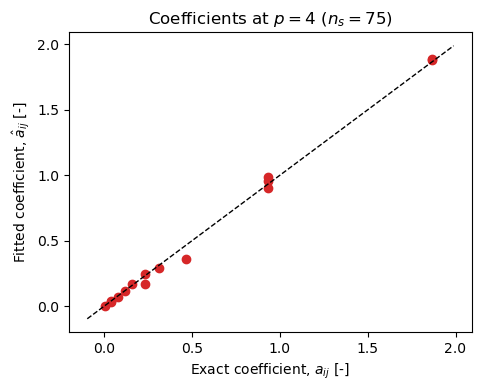

In [13]:
# Fitted against exact coefficients at p = 4, the last entry of results.
p4 = results[-1]
fig, ax = plt.subplots(figsize=(5.2, 3.9))
ax.plot(p4[6], p4[5], "o", color="C3")
# The 45-degree line a perfect fit would follow, drawn a little beyond the data range.
lim = [min(p4[6].min(), p4[5].min()) - 0.1, max(p4[6].max(), p4[5].max()) + 0.1]
ax.plot(lim, lim, "k--", lw=1)
# Labels.
ax.set_xlabel(r"Exact coefficient, $a_{ij}$ [-]")
ax.set_ylabel(r"Fitted coefficient, $\hat a_{ij}$ [-]")
ax.set_title("Coefficients at $p=4$ ($n_s=%d$)" % p4[2])
plt.show()

The 15 fitted coefficients lie close to the 45-degree line, the largest of them, 1.87, almost on it; the
worst is a coefficient of about 0.47 that the fit puts at 0.36. We expect them to lie closer as the number of
training points grows: averaging over more points brings the sample averages of the products $\psi_i\psi_j$
closer to their expectations, so the basis polynomials are closer to orthogonal over the points the fit uses.

Training and validation runs compete for the same budget. On the plate every run is an Abaqus job, so the total is fixed: each run spent on validation is one fewer for training, and the other way round. We have just seen what too few validation runs do, an unreliable $\varepsilon$. Now we look at the training side. This demonstration used a generous $n_p=5$, which might imply a large number of solver runs. The next cell fixes the order at $p=4$, and repeats the whole fit 200 times at each oversampling ratio from 1 to 10, with a different seed every time. It reports the median $\varepsilon$ on the reference set and the 10th-to-90th percentile range.

p = 4, 15 terms, exact truncation loss = 0.0128
  n_p   n_s    eps: 10th pct   median   90th pct
   1.0   15           0.0403    0.0833     1.3458
   1.5   23           0.0290    0.0422     0.0788
   2.0   30           0.0273    0.0378     0.0599
   3.0   45           0.0222    0.0319     0.0528
   5.0   75           0.0184    0.0263     0.0381
  10.0  150           0.0151    0.0206     0.0299


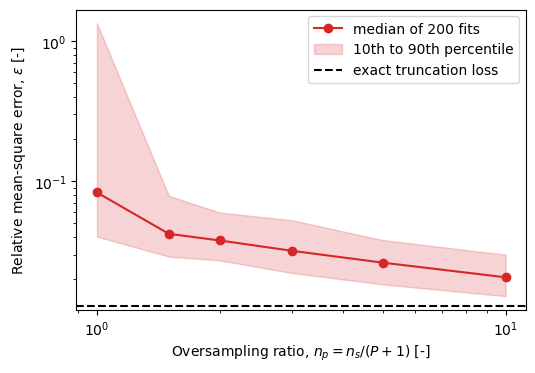

In [14]:
# The order of this experiment, the highest of the four, with its basis, its number of terms P+1 and the
# exact truncation loss it cannot beat.
P_RATIO = ORDERS[-1]
alphas_r = total_order_indices(2, P_RATIO)
n_terms_r = len(alphas_r)
trunc_r = exact_truncation_loss(P_RATIO, alphas_all, a_all, norms_all)
# Oversampling ratios n_p = n_s/(P+1), the number of independent redraws per ratio, and the seed offset (repeat r uses 100 + r).
ratios = [1.0, 1.5, 2.0, 3.0, 5.0, 10.0]
N_REPEATS = 200
SEED_REPEATS = 100
# The reference design matrix is the same for every fit: build it once.
psi_ref = design_matrix(xi_toy_valid, alphas_r)

table = []
for n_p in ratios:
    # Number of training runs at this ratio, and the validation error of every repeat.
    n_s = int(math.ceil(n_p * n_terms_r))
    eps_runs = []
    for r in range(N_REPEATS):
        # A fresh training set for every repeat, fitted and validated as before.
        xi_train = np.random.default_rng(SEED_REPEATS + r).standard_normal((n_s, 2))
        a_hat = fit_pce(xi_train, toy_output(xi_train), alphas_r)
        eps_runs.append(relative_mse(y_toy_valid, psi_ref @ a_hat))
    # 10th, 50th and 90th percentile of the 200 errors.
    table.append(np.percentile(eps_runs, [10, 50, 90]))
table = np.array(table)

# The table of percentiles.
print("p = %d, %d terms, exact truncation loss = %.4f" % (P_RATIO, n_terms_r, trunc_r))
print("  n_p   n_s    eps: 10th pct   median   90th pct")
for n_p, row in zip(ratios, table):
    print("  %4.1f  %3d     %12.4f  %8.4f  %9.4f" % (n_p, math.ceil(n_p * n_terms_r), *row))

# The same numbers as a figure, with both axes logarithmic.
fig, ax = plt.subplots(figsize=(5.8, 3.9))
ax.loglog(ratios, table[:, 1], "o-", color="C3", label="median of %d fits" % N_REPEATS)
ax.fill_between(ratios, table[:, 0], table[:, 2], color="C3", alpha=0.2, label="10th to 90th percentile")
# The floor no fit can go below: the exact truncation loss at this order.
ax.axhline(trunc_r, color="k", ls="--", label="exact truncation loss")
# Labels and legend.
ax.set_xlabel(r"Oversampling ratio, $n_p=n_s/(P+1)$ [-]")
ax.set_ylabel(r"Relative mean-square error, $\varepsilon$ [-]")
ax.legend()
plt.show()

With $n_p=1$, 15 runs for 15 unknowns, the fit passes exactly through the runs and can swing wildly between
them: the median error is 0.083, and one fit in ten exceeds 1.35, worse than always predicting the mean. At
$n_p=1.5$ the median falls to 0.042 and the 90th percentile to 0.079, more than an order of magnitude lower.
At $n_p=2$ the median is 0.038 with a range of 0.027 to 0.060, three times
the floor of 0.0128. With ten times as many runs as unknowns the median
is 0.021, still 1.6 times the floor.

More runs help, with diminishing returns. A ratio of 2 removes the exact-fit danger for a
modest cost; going from 2 to 10 would cost five times as many runs for a factor of 1.8 in the error. Thus the choice of 2 is a compromise, not a sharp optimum, and for Abaqus runs it decides the budget of [NB8](08_pce_surrogate_open_hole_tension.ipynb).

A last word on the single draws above: the $p=4$ fit at $n_p=5$ gave 0.0150, below this band's 10th percentile of 0.0184: a lucky draw, which should remind us that one fit is never the median, although one fit is what we can afford in real life.

**What Step 5 teaches.** Two things decide the error of a fit, and they are separate. The **order** sets the floor, the truncation loss: small when the model is close to a low-degree polynomial of its inputs, large when it is not. The harder the model, the higher the order we need, and with it more terms, $P+1$, and so more runs. The **number of runs** sets how close to that floor we get: at $n_p=5$ we were within 1.2 to 1.7 times it at every order, at $n_p=2$ three times it at $p=4$, and at $n_p=1$ the median was more than six times it.

The same split appears in the theory of [Cohen, Davenport & Leviatan (2013)](https://doi.org/10.1007/s10208-013-9142-3): whether least squares from random points is stable depends on the polynomials and the input distribution, not on the model, and the model enters the error only through its best approximation at that order, the truncation loss. That is why a ratio found on the toy model is a reasonable guide for the plate, and [NB8](08_pce_surrogate_open_hole_tension.ipynb) checks it on held-out Abaqus runs.

## Conclusion

This notebook learned the polynomial chaos expansion on a function whose expansion can be written down, so that
every step could be checked against an exact answer before a single Abaqus run is spent on it.

**What we established:**

- **For Gaussian inputs the basis is the probabilists' Hermite polynomials.** They are orthogonal on average,
  $\mathrm E[He_mHe_n]=n!\,\delta_{mn}$, which Gauss quadrature reproduced exactly (a diagonal table of 1, 1, 2, 6, 24).
  So the mean of an expansion is its constant coefficient and its variance is the sum of $a_j^2\,\mathrm E[\psi_j^2]$,
  with no further integration.
- **The order needed is set by how curved the output is over the spread of the inputs.** For $e^{\lambda\xi}$ a
  straight line loses 4.4% of the variance at $\lambda=0.3$ but 41.8% at $\lambda=1$, which needs $p=3$ to get
  below 5%.

- **The number of terms is the price of many inputs.** A total-order expansion has $(p+d)!/(p!\,d!)$ terms:
  16, 136 and 816 for our 15 inputs at orders 1 to 3, against 12, 78 and 364 for Thapa et al.'s 11.
- **Point collocation fits the coefficients by least squares from random runs, and the order and the number of
  runs limit the accuracy separately.** The order sets a floor, the truncation loss; the runs set how close to it the
  fit gets. With five runs per unknown, $\varepsilon$ on 200,000 points was 1.17 to 1.65 times the floor at every
  order, and fell from 0.63 at $p=1$ to 0.015 at $p=4$.

**Lessons learnt for the plate:**

- **Read an $\varepsilon$ from 100 validation runs with caution.** At $p=4$ the median $\varepsilon$ from 100 points
  was 0.0055, about a third of the 0.0150 measured on 200,000 points, and eight sets in ten read below the floor that
  no fit can beat. The error of a truncated expansion sits at the rare inputs far from the centre (the farthest 1% of
  the points carried 79% of the squared error at $p=4$), and a small set usually misses them. A low $\varepsilon$ from
  the plate's runs is therefore an optimistic estimate, while a high one is a real warning.
- **An oversampling ratio of 2 is a compromise, not an optimum.** At $p=4$, $n_p=1$ gave a median $\varepsilon$ of
  0.083 and one fit in ten worse than the mean; $n_p=2$ gave 0.038, three times the floor of 0.0128; $n_p=10$ gave
  0.021, for five times the runs. On Abaqus every run costs minutes, so $n_p=2$ is where the plate starts.

- **Check the method against a known answer first.** The puzzle of fits that beat their own floor was solvable only
  because the floor was known. On the plate there is no exact answer, so what this notebook found about the method is
  what we carry over.

**What's next.** [NB8](08_pce_surrogate_open_hole_tension.ipynb) builds the surrogate of NB6's open-hole tension plate: it turns these term counts into a budget of
Abaqus runs, measures how many runs the machine can do at once, and fits and validates the order-1 expansion.